In [1]:
pip install pandas numpy scikit-learn matplotlib seaborn kagglehub

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
# %% [markdown]
# # Basic Crop Yield Prediction Model
# Dataset: Agricultural Yield Prediction Dataset (247K rows) - Kaggle
# Models: Linear Regression (baseline) + Random Forest (default settings)
#
# Install once:  pip install pandas numpy scikit-learn matplotlib seaborn kagglehub

# %% 1. Imports
import glob
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

In [3]:
# %% 2. Load data
# Option A: download automatically from Kaggle (needs Kaggle login/API token)
try:
    import kagglehub
    DATA_DIR = kagglehub.dataset_download(
        "hvanman2code/agricultural-yield-prediction-dataset-247k-rows"
    )
except Exception as e:
    print("kagglehub download failed:", e)
    # Option B: put the folder path where you manually extracted the Kaggle zip
    DATA_DIR = "data"

csv_files = glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True)
print("CSV files found:", csv_files)
assert csv_files, "No CSV found. Download the dataset from Kaggle and set DATA_DIR."

# If several CSVs exist, the largest one is usually the main dataset
DATA_PATH = max(csv_files, key=os.path.getsize)
df = pd.read_csv(DATA_PATH)
print("Using:", DATA_PATH)
print("Shape:", df.shape)
print(df.head())

CSV files found: ['C:\\Users\\sreev\\.cache\\kagglehub\\datasets\\hvanman2code\\agricultural-yield-prediction-dataset-247k-rows\\versions\\1\\crop_yield_data.csv']
Using: C:\Users\sreev\.cache\kagglehub\datasets\hvanman2code\agricultural-yield-prediction-dataset-247k-rows\versions\1\crop_yield_data.csv
Shape: (247321, 18)
  weather_zone irrigation_method  soil_ph  irrigation_mm  \
0        humid             flood      NaN          116.0   
1     tropical              drip      NaN          259.0   
2     tropical             flood     7.05          276.0   
3    temperate              drip     5.81          136.0   
4        humid              drip      NaN           89.0   

   days_from_last_harvest seed_quality soil_type fertilized  nitrogen_kg_ha  \
0                   100.0          low     sandy         no          127.15   
1                     9.0       medium      loam         no          116.43   
2                     2.0       medium      peat         no           95.13   

In [4]:
# %% 3. Quick inspection
print(df.info())
print("\nMissing values per column:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

<class 'pandas.DataFrame'>
RangeIndex: 247321 entries, 0 to 247320
Data columns (total 18 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   weather_zone            247321 non-null  str    
 1   irrigation_method       247321 non-null  str    
 2   soil_ph                 227401 non-null  float64
 3   irrigation_mm           247319 non-null  float64
 4   days_from_last_harvest  247319 non-null  float64
 5   seed_quality            247321 non-null  str    
 6   soil_type               247321 non-null  str    
 7   fertilized              247321 non-null  str    
 8   nitrogen_kg_ha          247319 non-null  float64
 9   season                  247321 non-null  str    
 10  rainfall_mm             247319 non-null  float64
 11  avg_temp_c              247319 non-null  float64
 12  crop_type               247321 non-null  str    
 13  phosphorus_kg_ha        217624 non-null  float64
 14  humidity_pct            247319 

In [5]:
# %% 4. Detect target column
# Change TARGET manually if the auto-detection picks the wrong column.
TARGET = None
for col in df.columns:
    if "yield" in col.lower() and pd.api.types.is_numeric_dtype(df[col]):
        TARGET = col
        break
if TARGET is None:
    TARGET = df.select_dtypes(include=np.number).columns[-1]
print("Target column:", TARGET)

# Drop rows with missing target, drop ID-like columns
df = df.dropna(subset=[TARGET])
id_like = [c for c in df.columns
           if c != TARGET and (c.lower() in ("id", "index", "unnamed: 0")
                               or df[c].nunique() == len(df))]
if id_like:
    print("Dropping ID-like columns:", id_like)
    df = df.drop(columns=id_like)

Target column: crop_yield_tons


In [6]:
# %% 5. Split features into numeric / categorical
X = df.drop(columns=[TARGET])
y = df[TARGET]

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

# Date-like text columns would explode into thousands of categories, so drop them
for c in cat_cols.copy():
    if X[c].nunique() > 50:
        print(f"Dropping high-cardinality column: {c} ({X[c].nunique()} unique)")
        X = X.drop(columns=[c])
        cat_cols.remove(c)

print("Numeric features:", num_cols)
print("Categorical features:", cat_cols)

Numeric features: ['soil_ph', 'irrigation_mm', 'days_from_last_harvest', 'nitrogen_kg_ha', 'rainfall_mm', 'avg_temp_c', 'phosphorus_kg_ha', 'humidity_pct', 'pest_index', 'potassium_kg_ha']
Categorical features: ['weather_zone', 'irrigation_method', 'seed_quality', 'soil_type', 'fertilized', 'season', 'crop_type']


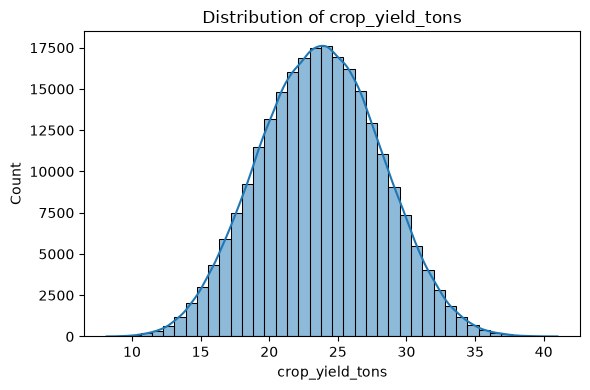

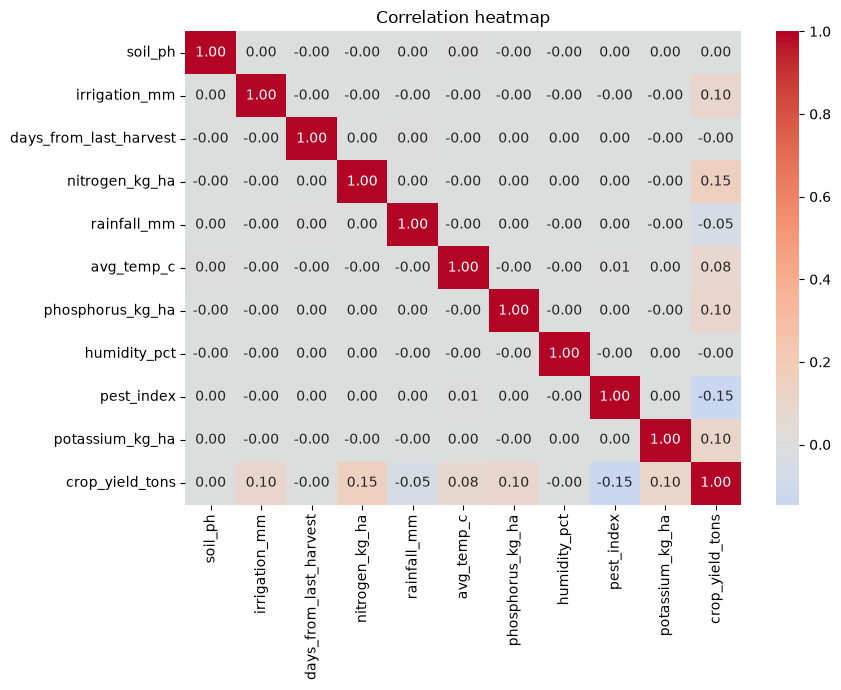

In [7]:
# %% 6. Quick EDA
plt.figure(figsize=(6, 4))
sns.histplot(y, bins=40, kde=True)
plt.title(f"Distribution of {TARGET}")
plt.tight_layout()
plt.show()

if len(num_cols) > 1:
    plt.figure(figsize=(9, 7))
    sns.heatmap(df[num_cols + [TARGET]].corr(), annot=True, fmt=".2f",
                cmap="coolwarm", center=0)
    plt.title("Correlation heatmap")
    plt.tight_layout()
    plt.show()

In [8]:
# %% 7. Train/test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (197855, 17) Test: (49464, 17)


In [9]:
# %% 8. Preprocessing
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocess = ColumnTransformer([
    ("num", numeric_pipe, num_cols),
    ("cat", categorical_pipe, cat_cols),
])


In [10]:
# %% 9. Basic models (default settings, no tuning)
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest (default)": RandomForestRegressor(
        n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1
    ),
}


def evaluate(y_true, y_pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }


results, fitted, preds = [], {}, {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    fitted[name], preds[name] = pipe, y_pred

    train_r2 = r2_score(y_train, pipe.predict(X_train))
    m = evaluate(y_test, y_pred)
    m.update({"Model": name, "Train R2": train_r2})
    results.append(m)

results_df = pd.DataFrame(results).set_index("Model")[["Train R2", "R2", "RMSE", "MAE"]]
results_df = results_df.rename(columns={"R2": "Test R2"})
print("\n=== Basic model results ===")
print(results_df.round(4))
results_df.to_csv("basic_model_results.csv")


=== Basic model results ===
                         Train R2  Test R2    RMSE     MAE
Model                                                     
Linear Regression          0.4401   0.4378  3.3111  2.6598
Random Forest (default)    0.9718   0.7994  1.9779  1.5671


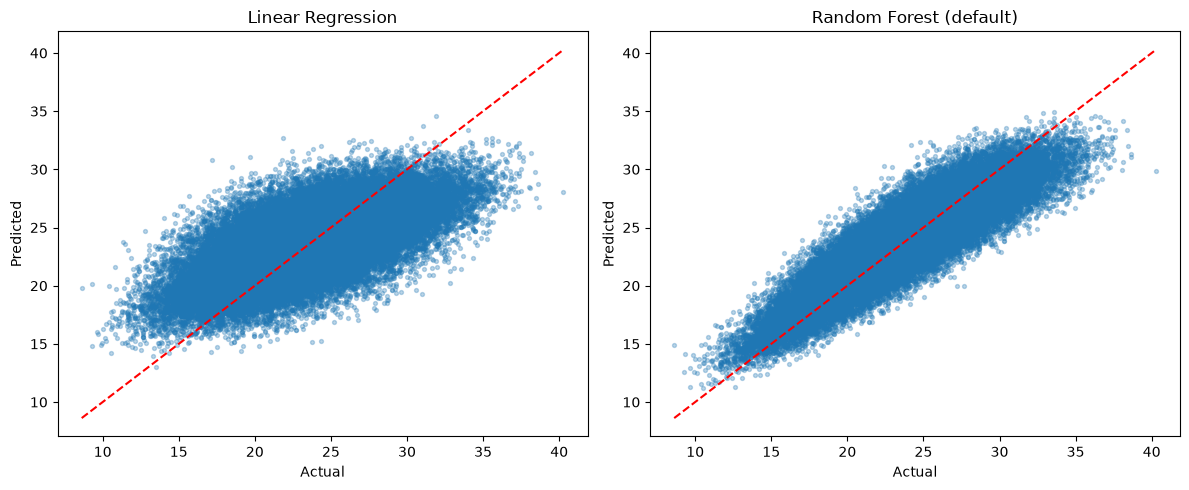

In [11]:
# %% 10. Actual vs predicted plots
fig, axes = plt.subplots(1, len(models), figsize=(6 * len(models), 5))
axes = np.atleast_1d(axes)
for ax, (name, y_pred) in zip(axes, preds.items()):
    ax.scatter(y_test, y_pred, alpha=0.3, s=8)
    lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
    ax.plot(lims, lims, "r--")
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")
    ax.set_title(name)
plt.tight_layout()
plt.show()

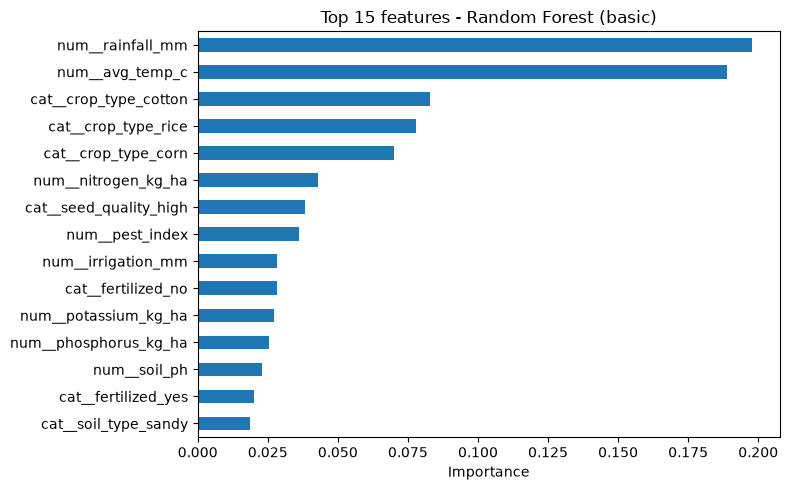

num__rainfall_mm          0.197870
num__avg_temp_c           0.188777
cat__crop_type_cotton     0.082986
cat__crop_type_rice       0.078047
cat__crop_type_corn       0.069980
num__nitrogen_kg_ha       0.042772
cat__seed_quality_high    0.038248
num__pest_index           0.036300
num__irrigation_mm        0.028347
cat__fertilized_no        0.028213
num__potassium_kg_ha      0.027051
num__phosphorus_kg_ha     0.025348
num__soil_ph              0.022904
cat__fertilized_yes       0.019972
cat__soil_type_sandy      0.018807
dtype: float64


In [12]:
# %% 11. Random Forest built-in feature importance (preview of the XAI step)
rf_pipe = fitted["Random Forest (default)"]
feature_names = rf_pipe.named_steps["prep"].get_feature_names_out()
importances = rf_pipe.named_steps["model"].feature_importances_
imp = (pd.Series(importances, index=feature_names)
       .sort_values(ascending=False).head(15))

plt.figure(figsize=(8, 5))
imp[::-1].plot(kind="barh")
plt.title("Top 15 features - Random Forest (basic)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()
print(imp)